# IBM Q 5-qubit "bowtie" (ibmqx2 Yorktown / ibmqx4 Tenerife): a Quantcore-PDK rebuild, step by step

**What the chip is.** IBM's first cloud processor (2016–2021): five fixed-frequency transmons and two bus resonators,
each bus coupling three qubits — Q0, Q1, Q2 on one, Q2, Q3, Q4 on the other — so the coupling graph is two triangles
sharing Q2 (the *bowtie*). Each qubit has its own readout resonator, read and driven through its own line; two-qubit
gates are cross-resonance gates on the bus-mediated exchange J.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica** (spec `docs/designs/ibm/ibm_bowtie_5q.md`).
No layout of the chip is public; IBM's published device data set the topology and the targets, the layout is ours:
Quantum Metal's `TransmonPocket6` (IBM's floating two-pad pocket transmon, through `metal:`) with **Quantcore trilayer
junctions** sized per qubit by the PDK junction rule, qcc meander routes for the buses and readouts, a `LineTee` fork
that lets one λ/2 bus reach three qubits, KQC finger capacitors, Quantcore `BondPad`s, the PDK die frame (9 × 8 mm,
QCT), sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| topology | coupling map 0-1, 0-2, 1-2, 2-3, 2-4, 3-4; two buses (Q0, Q1, Q2) and (Q2, Q3, Q4); one readout per qubit, individual lines | each bus is a λ/2 line from Q2 to a tee whose two short stubs reach the other two qubits (both ends at a voltage antinode) |
| f_q, α, J | ibmqx2 Hamiltonian / properties (Qiskit `FakeYorktown`, 2021-03-15): f_q 5.033–5.292 GHz, α −330 … −376 MHz, J 1.24–2.01 MHz | f_q matched per qubit with its junction; α ≈ −145 MHz (R_n ≤ 50 kΩ caps L_J ≤ 7.5 nH, so C_Σ is larger at the same f_q); J from the bus coupling pads. LOM 4 tries the two alternatives (#49) |
| buses | 7.0 GHz (Q0, Q1, Q2) and 6.6 GHz (Q2, Q3, Q4) (ibmqx4, arXiv:1805.10478 citing IBM's backend README) | the same targets |
| readout | ibmqx2 measurement LO 6.437–6.579 GHz (ibmqx4 table: 6.439–6.580 GHz, χ 408–512 kHz) | λ/2 resonators to a series finger capacitor and a 50 Ω pad, one per qubit |
| junctions | Al/AlOx (not given) | Quantcore Nb/AlOx/Nb trilayer junctions, R_n 40–50 kΩ (PDK rule: Δ 1.4 meV) |
| pads | (no layout) | **PDK pad rule**: five bond pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | Q2 at the die centre; the layout is symmetric, so the content is centred (Design 8) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** The device data come from `qiskit-ibm-runtime` (Apache-2.0; local copy
`build/external/qiskit_fake_backends/`) and the cited papers; the layout and code are ours (GPL, as the repository).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die, the five bond pads, the readout line (a series finger capacitor and its short 50 Ω
line per pad), the five pocket transmons with their trilayer junctions, their λ/2 readouts, the two three-qubit buses
with their tees, and then the whole chip (the centring, the targets and sim groups, the save). The the two
alternatives for α (LOM 4) stay what-ifs on copies, after the save. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `ibm_bowtie_5q.v1.ipynb`; both save the same
`ibm_bowtie_5q.json`.

## Setup

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/ibm")

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The source targets

**Source targets**: ibmqx2 (Qiskit `FakeYorktown` conf/props, 2021-03-15; the Hamiltonian's variables ÷ 2π) and the
ibmqx4 bus frequencies.

In [5]:
F_Q = {"Q0": 5.2823, "Q1": 5.2475, "Q2": 5.0334, "Q3": 5.2920, "Q4": 5.0785}          # GHz
ALPHA = {"Q0": -330.8, "Q1": -330.4, "Q2": -376.1, "Q3": -329.7, "Q4": -333.1}        # MHz
F_RO = {"Q0": 6.5304, "Q1": 6.4817, "Q2": 6.4365, "Q3": 6.5789, "Q4": 6.5301}        # GHz, meas LO centres
J_SRC = {"Q0-Q1": 1.905, "Q0-Q2": 1.820, "Q1-Q2": 1.236, "Q2-Q3": 1.820, "Q2-Q4": 1.812, "Q3-Q4": 2.009}  # MHz
F_BUS = {"BusA": 7.0, "BusB": 6.6}               # GHz (ibmqx4: Q0-Q1-Q2 bus 7.0, Q2-Q3-Q4 bus 6.6)

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, so each pad's line to its capacitor is drawn as soon as both exist (segment 3),
the readouts once the qubits are there (segment 5) and the buses once the tees are (segment 6). Every position is
fixed by `XC`, `YC`, `DX` and the pocket geometry, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 9 × 8 mm die with its frame, Q2 at its centre |
| 2 | five 50 Ω bond pads, one per qubit readout (Q0, Q3 on the top edge, Q1, Q2, Q4 on the bottom) |
| 3 | the readout line: a series finger capacitor 250 µm in from each pad and its short line to the pad |
| 4 | the five `TransmonPocket6` pockets with their trilayer junctions (L_J solved for IBM's f_q) |
| 5 | the five λ/2 readouts, qubit readout pad → finger capacitor |
| 6 | the coupling: two `LineTee`s and the two λ/2 buses with their stubs (the bowtie's two triangles) |
| 7 | the control routing: none (each qubit is driven through its readout line) |
| 8 | the whole chip: the centring, the targets and sim groups, the save |

## Design 1 · The die and its frame

A 9 × 8 mm die (five readout pads on the top and bottom edges, the bowtie in between). The build draws the PDK frame
round it: dicing L's (1000/0), alignment grids (1001/0), chip boundary (100/0), the device ID `IBM5Q` on a free edge.

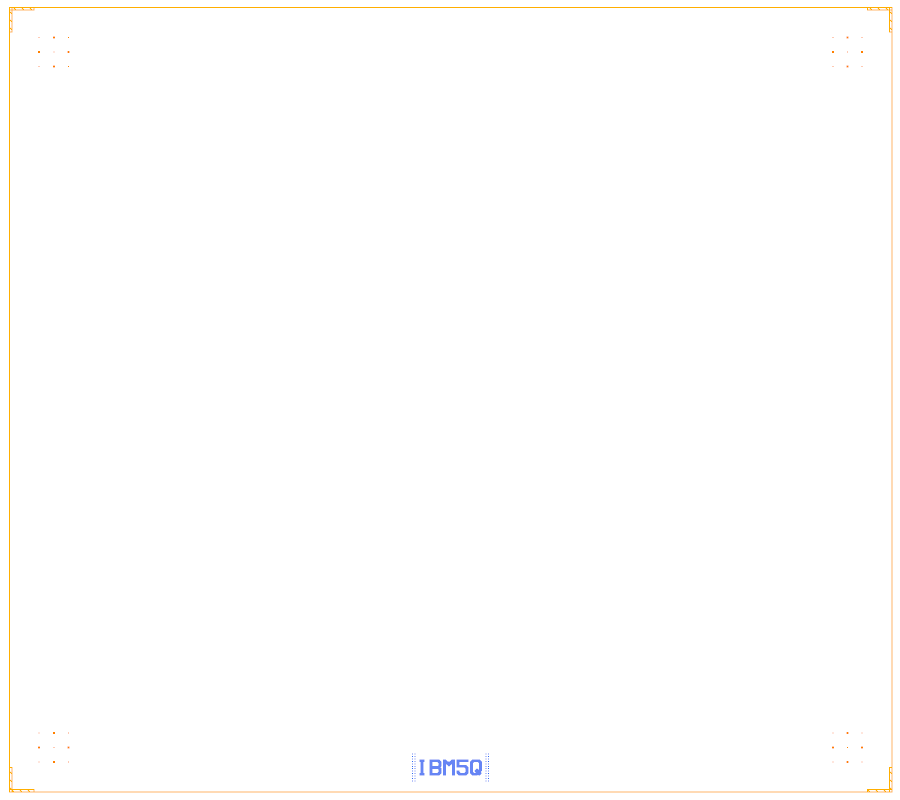

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_die.png')

In [6]:
W, H = 9000, 8000
XC, YC = 4500, 4000                              # Q2 at the die centre
DX = 2100                                        # Q2 ↔ the outer qubits in x
d = Designer("ibm_bowtie_5q", box=(0, 0, W, H), chip={"name_chip": "IBM5Q"}, live=LIVE)
layout_step(d, OUT / "ibm_bowtie_5q_die.png", size=(900, 800), width=320)

## Design 2 · Bond pads: the PDK pad rule

One 50 Ω `BondPad` per qubit readout: Q0 and Q3 read out through the top edge, Q1, Q2 and Q4 through the bottom edge,
each in line with its qubit. The PDK puts every pad's outer etch edge **`frame.pad_edge` = 100 µm from the die
edge**; `edge="auto"` slides each pad perpendicular to its nearest edge until that holds, keeping its position along
the edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_Q0 | `BondPad` | n | 100.0 | ✓ |
| P_Q1 | `BondPad` | s | 100.0 | ✓ |
| P_Q2 | `BondPad` | s | 100.0 | ✓ |
| P_Q3 | `BondPad` | n | 100.0 | ✓ |
| P_Q4 | `BondPad` | s | 100.0 | ✓ |

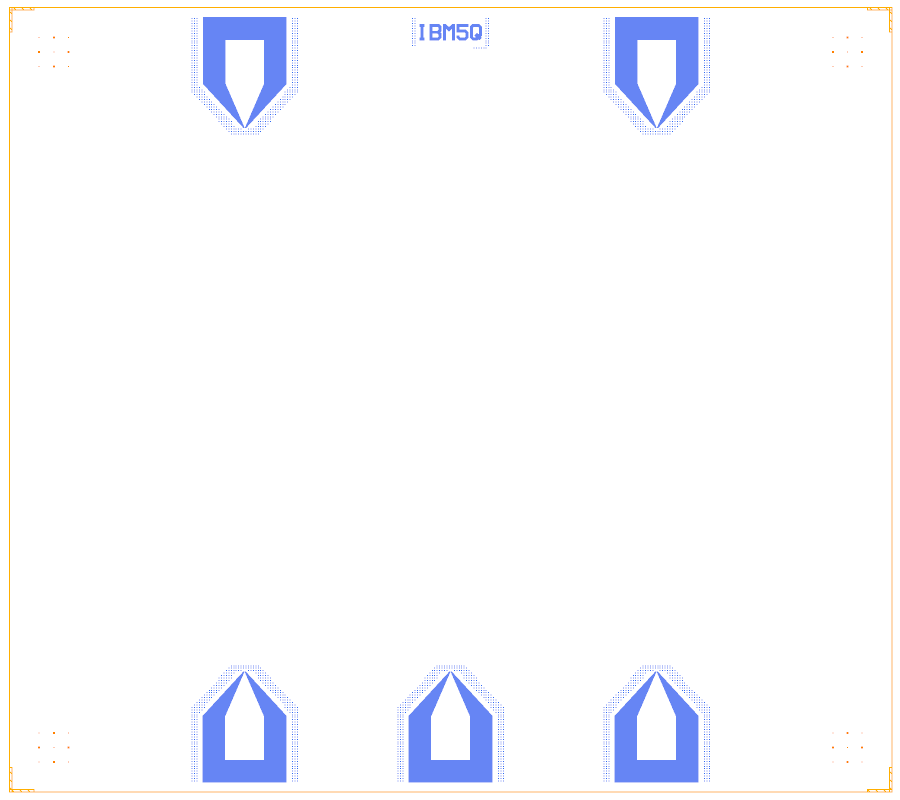

**On the chip so far:** 5 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 5 component(s) `P_Q0`, `P_Q1`, `P_Q2`, `P_Q3`, `P_Q4`.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_pads.png')

In [7]:
UP = ("Q0", "Q3")                                # read out through the top edge
X = {"Q0": XC - DX, "Q1": XC - DX, "Q2": XC, "Q3": XC + DX, "Q4": XC + DX}
Y_PAD = {n: H - 1150 if n in UP else 1150 for n in X}
bp = {n: d.add(f"P_{n}", "BondPad", at=(X[n], Y_PAD[n]), rot=180 if n in UP else 0, edge="auto") for n in X}
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "ibm_bowtie_5q_pads.png", size=(900, 800), width=320)

## Design 3 · Readout: the finger capacitors and their pad lines

**Finger capacitors.** Each readout ends
in a series KQC `FingerCapacitorSquare` 250 µm in from its pad (the readout's coupling to its 50 Ω line). Each is in line with its qubit and its pad, so it needs no qubit and comes first: a
short 50 Ω line `L_<q>` joins it to its pad (the readout λ/2 will end on its other side, Design 5).

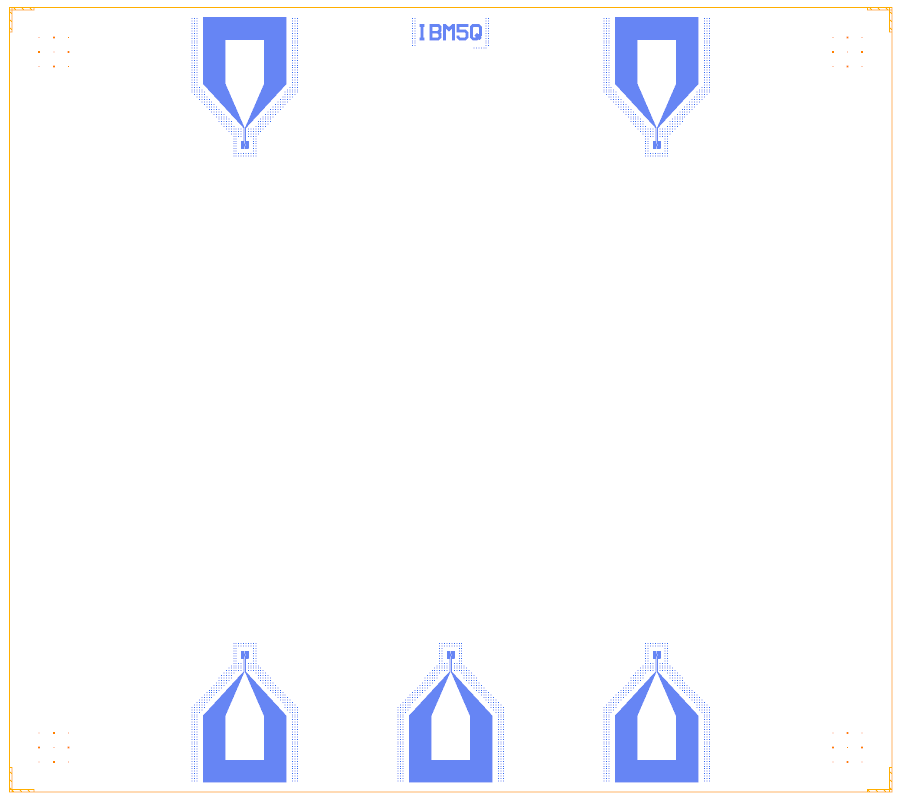

**On the chip so far:** 5 pads · 0 qubits · 5 other components · 5 routes · 0 declared couplings. **This step added** 5 component(s) `C_Q0`, `C_Q1`, `C_Q2`, `C_Q3`, `C_Q4` and 5 route(s) `L_Q0`, `L_Q1`, `L_Q2`, `L_Q3`, `L_Q4`.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_s3_readout_line.png')

In [8]:
fc = {n: d.add(f"C_{n}", "FingerCapacitorSquare", at=(X[n], Y_PAD[n] + (-250 if n in UP else 250)), rot=90)
      for n in X}
for name in X:
    up = name in UP
    d.route(f"L_{name}", fc[name].b if up else fc[name].a, bp[name].a, r=50)
layout_step(d, OUT / "ibm_bowtie_5q_s3_readout_line.png", size=(900, 800), width=320)

## Design 4 · Qubit placement: five pockets with trilayer junctions

**Junctions.** One Quantcore trilayer junction per qubit, its L_J solved with the LOM (LOM 1 a) so that f_q lands on
IBM's frequency. `trilayer_junction(cell, lj_nH)` returns the cell parameters that draw it (fingers on 2/0 + 4/0,
spacer 50/0 with the 51–53/0 gradient) and the values the LOM uses; all five R_n are inside the PDK window.

In [9]:
LJ = {"Q0": 6.09, "Q1": 6.18, "Q2": 6.59, "Q3": 6.07, "Q4": 6.63}                   # nH
JUNCTIONS = {q: trilayer_junction("metal:TransmonPocket6", lj_nH=lj) for q, lj in LJ.items()}
for q, (p, j) in JUNCTIONS.items():
    print(q, p["junction_params"], "→ drawn", j, f"R_n {rn_from_lj(j['Lj_nH']) / 1e3:.1f} kΩ")

Q0 {'lj_nH': 6.09} → drawn {'Lj_nH': 6.1222, 'Cj_fF': 16.5} R_n 40.9 kΩ
Q1 {'lj_nH': 6.18} → drawn {'Lj_nH': 6.2356, 'Cj_fF': 16.2} R_n 41.7 kΩ
Q2 {'lj_nH': 6.59} → drawn {'Lj_nH': 6.6024, 'Cj_fF': 15.3} R_n 44.1 kΩ
Q3 {'lj_nH': 6.07} → drawn {'Lj_nH': 6.1222, 'Cj_fF': 16.5} R_n 40.9 kΩ
Q4 {'lj_nH': 6.63} → drawn {'Lj_nH': 6.6024, 'Cj_fF': 15.3} R_n 44.1 kΩ


**The pockets.** IBM's floating two-pad transmon: 750 × 160 µm pads, a 20 µm gap, in a 950 µm pocket (C_Σ ≈ 140 fF in
the LOM). Connection pads on the pad edges: bus pads 150 µm wide (they set J), readout pads 140 µm (they set χ). Q2
has two bus pads (west, east) at its top and its readout at the bottom; the outer qubits face their tee.

<metal:TransmonPocket6 Q2 ports=['be', 'bw', 'ro', 'squid_a', 'squid_b']>


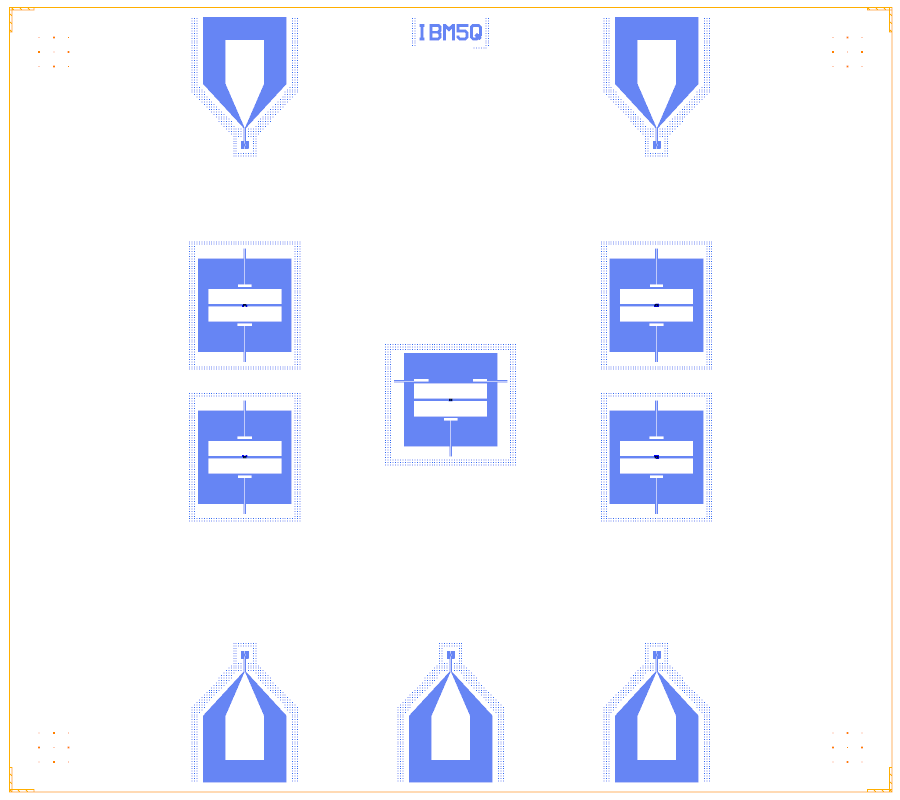

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 5 routes · 0 declared couplings. **This step added** 5 component(s) `Q0`, `Q1`, `Q2`, `Q3`, `Q4`.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_s4_qubits.png')

In [10]:
POCKET = dict(pad_width=750, pad_height=160, pad_gap=20, pocket_width=950, pocket_height=950)
BUS_PAD, RO_PAD = 150, 140                       # connection pad widths: bus (sets J), readout (sets χ)
YT = YC + 190                                    # the buses run straight at Q2's bus-pad height
STUB = 150                                       # tee → outer qubit stub
cpad = lambda name, loc_w, loc_h, width: {name: {"loc_W": loc_w, "loc_H": loc_h, "pad_width": width}}
yo = YT + 50 + STUB + 575                        # outer qubits: their bus pin sits STUB above / below the tee
place = {"Q0": (XC - DX, yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q1": (XC - DX, 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q2": (XC, YC, {**cpad("bw", -1, 1, BUS_PAD), **cpad("be", 1, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q3": (XC + DX, yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q4": (XC + DX, 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)})}
q = {}
for name, (x, y, cpads) in place.items():
    params, junction = JUNCTIONS[name]
    q[name] = d.add(name, "metal:TransmonPocket6", at=(x, y), junction=junction, connection_pads=cpads,
                    **POCKET, **params)
print(q["Q2"])
layout_step(d, OUT / "ibm_bowtie_5q_s4_qubits.png", size=(900, 800), width=320)

## Design 5 · Readout: five λ/2 readouts

- **Readouts:** a λ/2 meander from each qubit's readout pad to its finger capacitor (lengths set for IBM's readout
  frequencies), then the short 50 Ω line to the pad (Design 3).

Each is a meander with no waypoints: the router draws the shortest path between the two pins and puts the length it
leaves over into one KQC `Meander`.

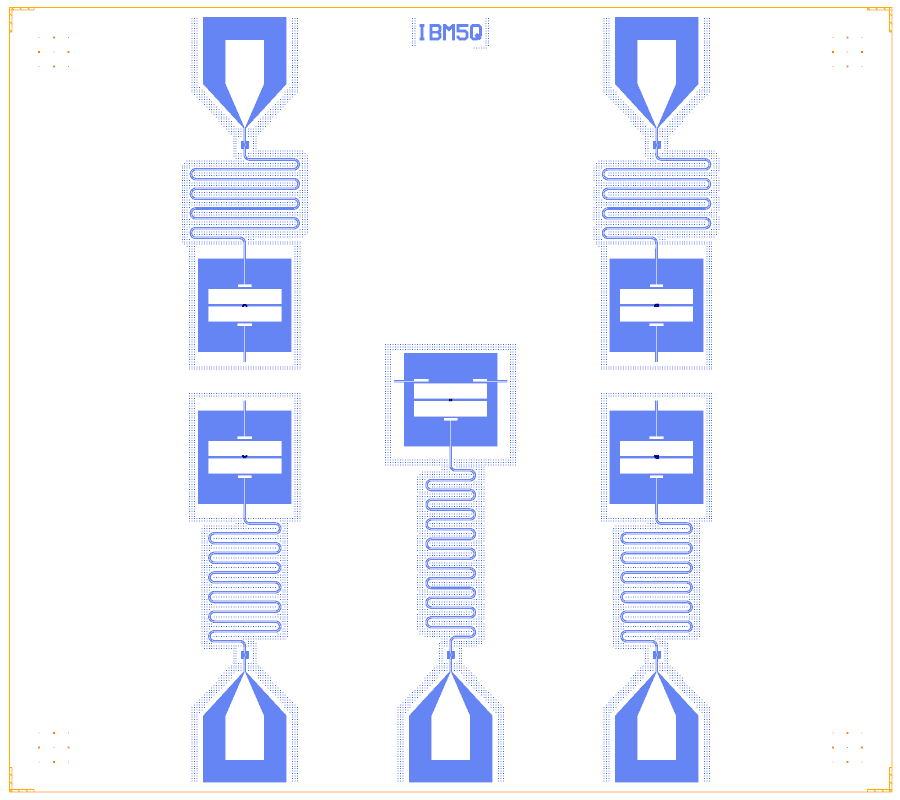

**On the chip so far:** 5 pads · 5 qubits · 5 other components · 10 routes · 0 declared couplings. **This step added** 5 route(s) `R_Q0`, `R_Q1`, `R_Q2`, `R_Q3`, `R_Q4`.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_s5_readouts.png')

In [11]:
L_RO = {"Q0": 9420, "Q1": 9494, "Q2": 9562, "Q3": 9348, "Q4": 9420}                   # λ/2 readouts (F_RO)
for name, qq in q.items():
    up = name in UP
    d.route(f"R_{name}", qq.ro, fc[name].a if up else fc[name].b, meander=L_RO[name], r=50)
layout_step(d, OUT / "ibm_bowtie_5q_s5_readouts.png", size=(900, 800), width=320)

## Design 6 · Coupling: two tees and the two three-qubit buses

**Tees.** A Metal `LineTee` between each outer pair forks a bus to both qubits.

- **Buses:** a λ/2 meander from Q2's bus pad to the tee's `second_end` (lengths set for 7.0 / 6.6 GHz with the LOM),
  and two short stubs from the tee to the outer qubits' bus pads. Both λ/2 ends sit at voltage antinodes.

The bus meanders sit between the outer pockets and Q2's pocket (`xm`); the router adds one KQC `Meander` for the
length the path leaves over.

{'L_Q0': 138.5, 'L_Q1': 138.5, 'L_Q2': 138.5, 'L_Q3': 138.5, 'L_Q4': 138.5, 'R_Q0': 9420.0, 'R_Q1': 9494.0, 'R_Q2': 9562.0, 'R_Q3': 9348.0, 'R_Q4': 9420.0, 'BusA': 8190.0, 'BusA_Q0': 150.0, 'BusA_Q1': 150.0, 'BusB': 8750.0, 'BusB_Q3': 150.0, 'BusB_Q4': 150.0}


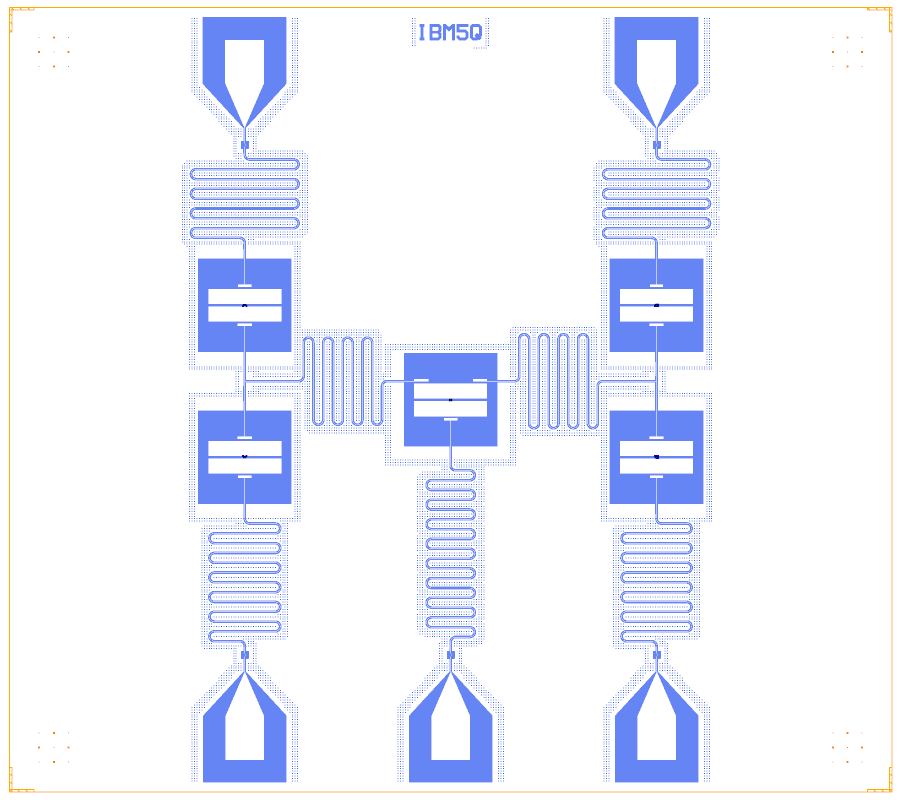

**On the chip so far:** 5 pads · 5 qubits · 7 other components · 16 routes · 0 declared couplings. **This step added** 2 component(s) `TA`, `TB` and 6 route(s) `BusA`, `BusA_Q0`, `BusA_Q1`, `BusB`, `BusB_Q3`, `BusB_Q4`.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_s6_buses.png')

In [12]:
tee = {bus: d.add(f"T{bus[-1]}", "metal:LineTee", at=(XC + sx * DX, YT), rot=90 if sx < 0 else -90)
       for bus, sx in (("BusA", -1), ("BusB", 1))}
L_BUS = {"BusA": 8190, "BusB": 8750}             # λ/2 bus lengths Q2 → tee (set for F_BUS with the LOM)
for bus, sx, pin, (top, bot) in (("BusA", -1, "bw", ("Q0", "Q1")), ("BusB", 1, "be", ("Q3", "Q4"))):
    t = tee[bus]
    xm = XC + sx * (DX - 475 - 50)               # meander between the outer pockets and Q2's pocket
    d.route(bus, q["Q2"][pin], t.second_end, meander=L_BUS[bus], r=50, nodes=[(xm, YT)])
    d.route(f"{bus}_{top}", t.prime_end if sx < 0 else t.prime_start, q[top].bus, r=50)
    d.route(f"{bus}_{bot}", t.prime_start if sx < 0 else t.prime_end, q[bot].bus, r=50)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "ibm_bowtie_5q_s6_buses.png", size=(900, 800), width=320)

## Design 7 · Routing: control lines

None: the source chip drives each qubit through its own readout line, so no separate XY or flux line is drawn.
Nothing is routed here.

## Design 8 · The whole chip: centring, targets, sim groups, save

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it; Q2 sits at the
die centre and the layout is mirror-symmetric, so it returns (0, 0).

Targets: IBM's f_q and α per qubit, the readout and bus frequencies. FEM boxes: each triangle (three qubits, the bus,
tee and stubs: the C-matrix gives every bus pad's C_g) and Q2 with its readout and finger capacitor.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the capacitors and their pad lines were added before the qubits and the readouts before the tees and buses here), so `git diff` stays empty.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/ibm/ibm_bowtie_5q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer ibm_bowtie_5q: 17 instances, 16 routes, live=False> → examples\designs\ibm\ibm_bowtie_5q.json


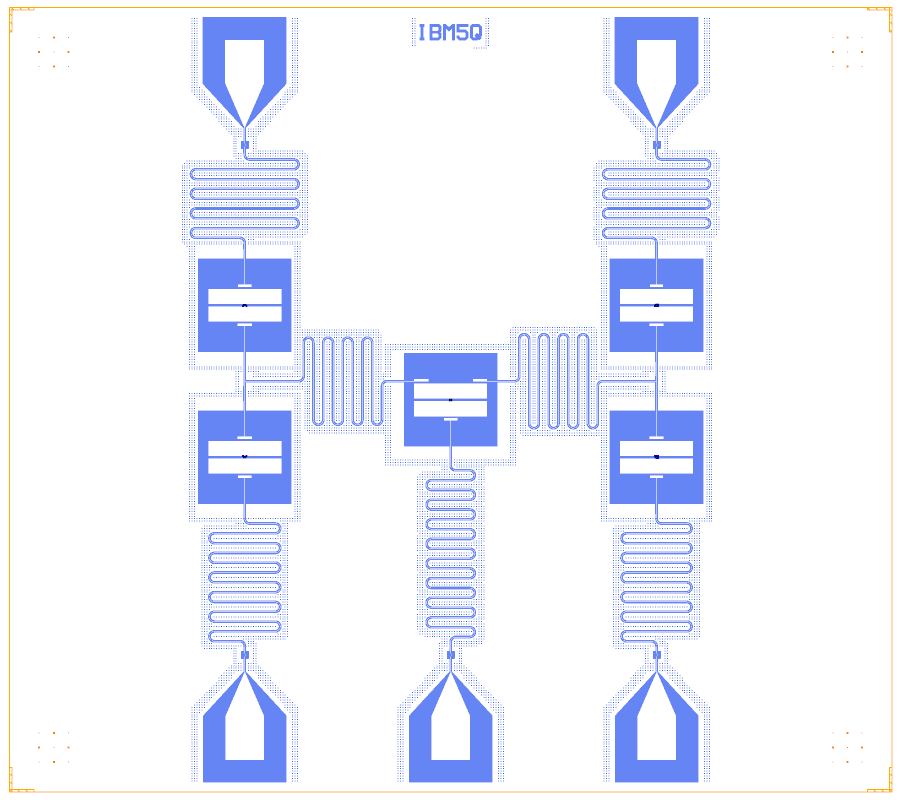

**On the chip so far:** 5 pads · 5 qubits · 7 other components · 16 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/ibm/ibm_bowtie_5q_s8_chip.png')

In [13]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{n: {"f_q_GHz": F_Q[n], "alpha_MHz": ALPHA[n]} for n in F_Q},
          **{f"R_{n}": {"f_GHz": F_RO[n]} for n in F_Q}, **{b: {"f_GHz": f} for b, f in F_BUS.items()})
d.sim_group("triangle_A", ["Q0", "Q1", "Q2", "BusA", "TA", "BusA_Q0", "BusA_Q1"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("triangle_B", ["Q2", "Q3", "Q4", "BusB", "TB", "BusB_Q3", "BusB_Q4"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("Q2_read", ["Q2", "R_Q2", "C_Q2"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN, same = save_design(d, OUT / "ibm_bowtie_5q.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "ibm_bowtie_5q_s8_chip.png", size=(900, 800), width=320)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the five pockets (the cell
  draws the trilayer junction across the pad gap itself);
- **PDK design warnings:** none expected (every R_n is in the window, every f_q target in 4–8 GHz, every pad at 100 µm).

From the v1 run: **0 errors · 10 warnings (`dangling_port`) · 0 PDK design warnings**; drawn R_n 40.9–44.1 kΩ.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`TransmonPocket6` → two floating pads (`island1` / `island2`) with the trilayer junction between them (the drawn
L_J / C_J), a node per connection pad. Each bus (Q2's pad → tee → two stubs) is one node: the λ/2 `TLres` of the
meander joins Q2's bus pad, the tee and both outer pads (the stubs are wires; their 2 × 150 µm are not in the
resonator length: the eigenmode job holds them). Each readout is a λ/2 between the qubit's pad and the finger
capacitor, whose other side is the 50 Ω pad.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; targets in brackets). The L_J of Design 4 were solved with these groups so
that f_q lands on IBM's frequencies.

From the v1 run: f_q 5.028–5.2685 GHz, within 23 MHz of IBM's; α −143 … −147 MHz (IBM −330 … −376 MHz, see LOM 4);
f_r 6.337–6.477 GHz, 1.6 % below IBM's measurement LOs: the λ/2 lengths were set before the Nb film's kinetic
inductance (PDK `kinetic`) entered the LOM, which makes every line ≈ 1.6 % slower (flagged, not retuned); κ
0.87–0.93 MHz; χ −0.69 … −0.89 MHz (ibmqx4's table gives 0.41–0.51 MHz).

In [ ]:
read = {f"{n}+R": [n, f"R_{n}", f"C_{n}", f"L_{n}", f"P_{n}"] for n in F_Q}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

**(b) The two buses and the exchange couplings.** Each triangle (three qubits, the bus, tee and stubs) is simulated as
one circuit: the bus mode and the qubits' dressed frequencies. J of each coupled pair is the half-splitting at the
avoided crossing (the second qubit's L_J is swept through the first's frequency, `exchange_coupling`), next to IBM's
Hamiltonian value; ZZ is the static ZZ at the design frequencies. J of the pairs through Q2 is taken on the pair with
its bus (the third qubit left out: ≈ 10 s per pair; its pad shifts the bus by a few tens of MHz), the outer pairs
Q0–Q1 and Q3–Q4 on the whole triangle (both must keep Q2's end of the bus: ≈ 2 min each). The two outer qubits of a
triangle share the tee, so in the LOM all three couple to the same bus node.

From the v1 run: the bus modes at 6.911 (A) and 6.511 GHz (B), 1.3 % below 7.0 / 6.6 GHz (the same kinetic inductance);
J Q0–Q1 1.80 (IBM 1.91), Q0–Q2 1.61 (1.82), Q1–Q2 1.55 (1.24), Q2–Q3 1.56 (1.82), Q2–Q4 1.57 (1.81) and Q3–Q4
3.78 MHz (2.01): the outer pair Q3–Q4 is detuned by only 0.18 GHz, so its avoided-crossing estimate runs high;
static ZZ −173 … +76 kHz.

In [ ]:
tri = {"A": ["Q0", "Q1", "Q2", "BusA", "TA", "BusA_Q0", "BusA_Q1"],
       "B": ["Q2", "Q3", "Q4", "BusB", "TB", "BusB_Q3", "BusB_Q4"]}
buses = simulate_groups(d, {f"triangle {k}": sel for k, sel in tri.items()}, max_modes=4)
for g, res in buses.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown(f"Bus targets: {F_BUS} GHz"))
PAIRS = {"Q0-Q1": tri["A"], "Q0-Q2": ["Q0", "Q2", "BusA", "TA", "BusA_Q0"],
         "Q1-Q2": ["Q1", "Q2", "BusA", "TA", "BusA_Q1"], "Q2-Q3": ["Q2", "Q3", "BusB", "TB", "BusB_Q3"],
         "Q2-Q4": ["Q2", "Q4", "BusB", "TB", "BusB_Q4"], "Q3-Q4": tri["B"]}
J = {p: exchange_coupling(d, sel, *p.split("-")) for p, sel in PAIRS.items()}
display(Markdown(exchange_md(J, J_SRC)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group — the five qubit + readout pairs and the
two triangles (QuCat; circles are qubits, squares the readouts and buses; filled markers are the QuTiP dressed values;
red bars the targets), (b) the dispersive shift |χ| of each readout. From the v1 run the qubits sit on their red bars,
the readouts and the buses 1.3–1.6 % below theirs (the Nb kinetic inductance, LOM 1 a).

In [ ]:
plot_lom({**results, **buses}, OUT / "ibm_bowtie_5q_lom.png", targets=d.data["targets"],
         title="ibm_bowtie_5q: LOM, pairs and triangles")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. J(Q0–Q2) comes out below IBM's 1.82 MHz. The knob is the bus pad: here Q0's goes from 150 to 120 µm, the other
direction, so J drops further — the LOM shows by how much in ≈ 10 s. From the v1 run: J(Q0–Q2) 1.61 → 1.35 MHz, ZZ −30 → −17 kHz. `design_copy` opens a second, non-live Designer
on the saved design; the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q0"].set(connection_pads={**place["Q0"][2], **cpad("bus", 0, -1, 120)})
J2 = {"Q0-Q2 (bus pad 150 µm)": J["Q0-Q2"],
      "Q0-Q2 (bus pad 120 µm)": exchange_coupling(d2, PAIRS["Q0-Q2"], "Q0", "Q2")}
display(Markdown(exchange_md(J2, {k: J_SRC["Q0-Q2"] for k in J2})))

## LOM 4 · the two alternatives for α

With PDK junctions (R_n 40–50 kΩ, so L_J ≤ 7.5 nH and E_J/h ≥ 22 GHz), a 5 GHz pocket needs a large C_Σ and its α is
only ≈ −145 MHz against IBM's −330 MHz. Both alternatives are shown; both are LOM what-ifs on a
copy of the design (the saved design is unchanged), and each is compared on the same footing: every qubit with its
readout, and both triangles at once for the static ZZ of every pair (one simulation per triangle).

A transmon has f_q ≈ √(8 E_J E_C) − E_C and α ≈ −E_C (a little more), with E_C/h = e²/2hC_Σ and
E_J/h = 163.46 GHz·nH / L_J. `resize` (below) infers E_C from a simulated (L_J, f_q) and sets the L_J that puts f_q
on the target; two passes absorb the junction's own C_J.

In [ ]:
EJ_LJ = 163.46                                   # E_J/h (GHz) × L_J (nH) = (Φ0/2π)²/h


def ec_from(f_GHz, lj_nH):
    """E_C/h (GHz) of a transmon from its f_q and L_J: the small root of f = √(8 E_J E_C) − E_C."""
    s = math.sqrt(8 * EJ_LJ / lj_nH)
    return ((s - math.sqrt(s * s - 4 * f_GHz)) / 2) ** 2


def resize(dd, f_target, groups, cell="metal:TransmonPocket6", passes=2):
    """LOM what-if: re-draw each qubit's trilayer junction in ``dd`` for ``f_target`` (GHz)."""
    for _ in range(passes):
        res = simulate_groups(dd, {q_: groups[q_] for q_ in f_target})
        for q_, ft in f_target.items():
            ec = ec_from(res[q_].params[f"{q_}.f_q_GHz"], dd.data["instances"][q_]["junction"]["Lj_nH"])
            params, jj = trilayer_junction(cell, lj_nH=EJ_LJ * 8 * ec / (ft + ec) ** 2)
            dd[q_].set(junction=jj, **params)
    return simulate_groups(dd, {q_: groups[q_] for q_ in f_target})


def plan_md(dd, res, window):
    """Junction, f_q and α per qubit against IBM's, with the R_n window flag."""
    rows = [f"| qubit | L_J (nH) | R_n (kΩ) | R_n in {window[0]}–{window[1]} kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |",
            "|---|---|---|---|---|---|"]
    for g, r in res.items():
        q_ = g.split("+")[0]
        lj = dd.data["instances"][q_]["junction"]["Lj_nH"]
        rn = rn_from_lj(lj) / 1e3
        rows.append(f"| {q_} | {lj:.2f} | {rn:.1f} | {'yes' if window[0] <= rn <= window[1] else 'no'} | "
                    f"{r.params[f'{q_}.f_q_GHz']:.4f} [{F_Q[q_]}] | {r.params[f'{q_}.alpha_MHz']:.0f} [{ALPHA[q_]}] |")
    return "\n".join(rows)


def zz_tri(dd):
    """Static ZZ of every pair, both triangles simulated whole (QuTiP dressed)."""
    return simulate_groups(dd, {f"triangle {k}": sel for k, sel in tri.items()}, max_modes=4)


base_zz = zz_tri(d)
display(Markdown("**The design (PDK window, C_Σ ≈ 140 fF):**\n\n" + zz_md(base_zz)))

**(A) A wider R_n window, 30–80 kΩ.** A larger L_J (up to 12 nH at 80 kΩ) lets a smaller pocket reach 5 GHz, and a
smaller pocket has the larger E_C IBM uses. The pads shrink from 750 × 160 to 380 × 100 µm (C_Σ ≈ 77 fF in the LOM,
E_C ≈ 0.25 GHz), and every junction is re-sized for IBM's f_q. From the v1 run: L_J 12.0–13.0 nH, R_n 80.4–86.5 kΩ:
on the PDK finger grid the drawn junctions land just above even the wider window (the table's "no"); α −316 …
−339 MHz, at IBM's; f_q within 1.3 % of IBM's; χ −3.2 … −4.4 MHz (the bus and readout pads are kept, the pocket
is smaller). In triangle A the three qubits come within 0.3 GHz of each other and hybridise (no ZZ), in triangle B
the static ZZ is 132–342 kHz.

In [ ]:
dA = design_copy(DESIGN, "_wide_rn")
for n in F_Q:
    dA[n].set(pad_width=380, pad_height=100)
resA = resize(dA, F_Q, {n: read[f"{n}+R"] for n in F_Q})
display(Markdown(plan_md(dA, resA, (30, 80))))
display(Markdown(groups_md(resA, d.data["targets"])))
display(Markdown(zz_md(zz_tri(dA))))

**(B) A larger C_Σ inside the PDK window.** The pocket grows (pads 1000 × 200 µm in a 1250 × 1150 µm pocket, C_Σ
≈ 190 fF) with the design's junctions (R_n 41–44 kΩ, in the window). A larger C_Σ lowers E_C: f_q falls to 4.37–4.57 GHz
and α to −107 … −109 MHz (from the v1 run; χ ≈ −0.2 MHz, ZZ −16 … +18 kHz), so the collision band |Δ| ≈ |α| moves to smaller detunings. It does not bring IBM's α back; it
trades f_q and |α| for charge-noise insensitivity.

In [ ]:
dB = design_copy(DESIGN, "_big_c")
for n in F_Q:
    dB[n].set(pad_width=1000, pad_height=200, pocket_width=1250, pocket_height=1150)
resB = simulate_groups(dB, {n: read[f"{n}+R"] for n in F_Q})
display(Markdown(plan_md(dB, resB, (40, 50))))
display(Markdown(groups_md(resB, d.data["targets"])))
display(Markdown(zz_md(zz_tri(dB))))

**Reading the two.** (A) is the only one that brings α near IBM's, at the price of junctions outside today's PDK
window (R_n 80–87 kΩ, smaller fingers). (B) stays inside the window but moves every qubit down and |α| further away
from IBM's. Neither is applied to the saved design: the rebuild keeps the PDK junctions and flags the α difference.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/ibm/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Four jobs: a Q3D C-matrix job per triangle (the bus pads' C_g to both qubit pads, the stubs, the tee) and, for Q2, a
C-matrix and an eigenmode job with its readout and finger capacitor. Simulation exports never carry cheese; exporting
again replaces a job folder, results included.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/ibm/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["triangle_A", "triangle_B", "Q2_read"])
jobs_eig = export_sims(DESIGN, ["Q2_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

Three C-matrices: each triangle (`triangle_A`, `triangle_B`: three pockets, the bus, the tee and the stubs: every bus
pad's C_g to both qubit pads) and `Q2_read` (Q2 with its readout and finger capacitor). Each net is named after its
LOM node (each pocket's `island1` / `island2`, the bus and readout pads), so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

`Q2_read` in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet across the pad gap, the lines the box cuts end
in 50 Ω, so each mode's Q gives κ through the finger capacitor. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q2_read`: the readout is a λ/2 between Q2's pad and its finger capacitor, and
the box's ports are where it cuts lines (Q2's pad line `L_Q2` and the two buses: the job table above lists them). The
readout then shows in the reflection at the pad line's port rather than as an S21 notch, so `driven_md` may report no
notch; κ comes from the eigenmode's Q (Results 2).

In [ ]:
f_r0 = results["Q2+R"].params.get("R_Q2.f_GHz")        # the LOM's readout frequency (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "Q2_read", jobs_eig["Q2_read"][0], keep_eig["Q2_read"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q2_read"]:
    display(Markdown(driven_md(keep_drv["Q2_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q2_read": ("Q2", "R_Q2", "Q2+R")}      # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = results[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "ibm_bowtie_5q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q2_read"]:
    qb, rr, _ = PAIRS["Q2_read"]
    fem_values.setdefault("Q2_read", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q2_read"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR (κ = f/Q through the finger capacitor).")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: each triangle on its own C-matrix, once that job is kept — the bus mode and the
three qubits' frequencies against LOM 1 b (the bus targets are 7.0 / 6.6 GHz).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = results[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=read[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

for k, sel_t in tri.items():
    if keep_q3d.get(f"triangle_{k}"):
        tri_fem = simulate(fill(d.lom(select=sel_t).model, DESIGN, keep_q3d[f"triangle_{k}"]), max_modes=4)
        display(Markdown(f"**triangle {k} on its C-matrix, QuCat normal modes** (LOM 1 b: the estimates):\n\n"
                         + modes_md(tri_fem)))

## Results 4 · Feedback: one step towards IBM's frequencies

The design carries IBM's targets (Design 8): f_q and α per qubit, the readout frequencies, the two bus frequencies.
**α stays out of the feedback copy:** inside the PDK window a 5 GHz pocket has α ≈ −145 MHz, and LOM 4 shows that
IBM's −330 MHz needs junctions outside it. `target_copy(DESIGN, TARGETS)` therefore writes the design with each qubit's
target set to f_q only (the readouts and buses keep theirs) to `build/ibm_bowtie_5q_target.json`, and the feedback
works on that copy; the design file keeps all of IBM's targets. From the v1 run the qubits are within 23 MHz of IBM's
and the readouts 1.6 % low, so the feedback mostly shortens the five readouts (meanders with no waypoints: the router
can) and nudges the L_J's.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the circuit
— five here, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per quantity (the
consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside their
tolerances (f_q ± 20 MHz, f_r ± 10 MHz); the proposal is written as revision 1, built and netlist-checked.
`pdk_lj_bounds` keeps the junctions inside the 40–50 kΩ window. The buses are not qubit–readout pairs (each joins
three qubits), so the feedback does not tune them (its notes say so): Results 4b does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {q: {"f_q_GHz": F_Q[q]} for q in F_Q}   # f_q only: IBM's α is out of the PDK window's reach (LOM 4)
DESIGN_T = target_copy(DESIGN, TARGETS)          # the readouts and buses keep the design's targets
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 4b · The buses: a first-order rule

Each bus is a λ/2 line (Q2's bus pad → the tee), so it resonates at f ∝ 1/ℓ: **ℓ ← ℓ · f_now / f_target**
(`rule_step`, exponent −1), with f_now the bus's normal mode in its triangle (LOM 1 b). From the v1 run the buses sit
at 6.911 and 6.511 GHz against 7.0 / 6.6 GHz, so both get ≈ 1.3 % shorter (still far above their waypoint paths). The
new lengths are set on a copy of the design (`design_copy`), the two triangles are simulated again (≈ a minute or two
each), and the copy is saved and DRC-checked.

In [ ]:
BUS_TRI = {"BusA": "triangle A", "BusB": "triangle B"}


def bus_f(res_t, bus):
    """The bus's normal-mode frequency (GHz) in its triangle's LOM (QuCat)."""
    return next((m.f_GHz for m in res_t.modes if m.label == bus), None)


d_b = design_copy(DESIGN, "_buses")              # the bus revision: the design file stays
before, after = {}, {}
for bus, g in BUS_TRI.items():
    l_now, f_now = float(d.data["routes"][bus]["length"]), bus_f(buses[g], bus)
    l_new = round(rule_step(l_now, f_now, F_BUS[bus], -1.0), 2)
    d_b[bus].set(meander=l_new)
    before[f"{bus} ℓ (µm)"], before[f"{bus} f (GHz)"], after[f"{bus} ℓ (µm)"] = l_now, f_now, l_new
res_b = simulate_groups(d_b, {g: tri[g[-1]] for g in BUS_TRI.values()}, max_modes=4)
for bus, g in BUS_TRI.items():
    after[f"{bus} f (GHz)"] = bus_f(res_b[g], bus)
display(Markdown(before_after_md(before, after)))
rev_b = d_b.save(Path("build") / "ibm_bowtie_5q_buses" / "rev1.json")
print("bus revision:", rev_b, "· DRC:", "clean" if check(str(rev_b)).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/ibm_bowtie_5q/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the `Q2_read` Q3D job are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

Then the bus rule repeated for each bus (`rule_iterate`: the next step uses the exponent of the last two points, a
secant), until the bus is within 10 MHz of its target or `MAX_ITER` steps are made (LOM; each step simulates its
triangle).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q2_read Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q2_read",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "ibm_bowtie_5q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

def bus_rev(bus):
    """evaluate(ℓ, it) for rule_iterate: a copy with the bus ℓ long, saved, and the bus mode of its triangle."""
    def evaluate(length, it):
        d_k = design_copy(DESIGN, f"_{bus}_rev{it}")
        d_k[bus].set(meander=round(length, 2))
        path = d_k.save(Path("build") / "ibm_bowtie_5q_buses" / f"{bus}_rev{it}.json")
        g = BUS_TRI[bus]
        return bus_f(simulate_groups(d_k, {g: tri[g[-1]]}, max_modes=4)[g], bus), path
    return evaluate


for bus, g in BUS_TRI.items():
    hist_b = rule_iterate(bus_rev(bus), f"{bus}.f_GHz", f"{bus}.length", float(d.data["routes"][bus]["length"]),
                          F_BUS[bus], 0.010, -1.0, max_iter=MAX_ITER, start=(bus_f(buses[g], bus), DESIGN))
    display(Markdown(f"**{bus}:**\n\n" + history_md(hist_b)))

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `examples/designs/ibm/ibm_bowtie_5q.json` (Design 8); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; 11 106 holes in the v1 run).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese never.
- **The same from the command line:** `qcc build examples/designs/ibm/ibm_bowtie_5q.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g triangle_A -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (PDK frame, QCT device ID): the bowtie, Q2 in the middle, the two meandered buses out to the tees between
Q0/Q1 and Q3/Q4, five λ/2 readouts to finger capacitors and pads. Then the left triangle, Q2's trilayer junction
across the 20 µm pad gap, a readout's finger capacitor and pad, and the fab mask round Q2 (the PDK band's
5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0, the junction layers).

In [ ]:
snap(d, OUT / "ibm_bowtie_5q.png", size=(1500, 1333))
snap(d, OUT / "ibm_bowtie_5q_triangle.png", box=(XC - DX - 700, YC - 1500, XC + 700, YC + 1900),
     size=(1200, 1450), width=520)
snap(d, OUT / "ibm_bowtie_5q_jj.png", box=(XC - 40, YC - 30, XC + 40, YC + 30), size=(800, 600), width=320)
snap(d, OUT / "ibm_bowtie_5q_cap.png", box=(XC - 400, 700, XC + 400, 1700), size=(800, 1000), width=320)
snap_file(Path("build") / "ibm_bowtie_5q_fab.oas", OUT / "ibm_bowtie_5q_cheese.png",
          box=(XC - 700, YC - 700, XC + 700, YC + 700), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the bowtie coupling graph, IBM's five qubit frequencies (within 23 MHz, from the v1 run), the readout
  frequencies (1.6 % low: the Nb kinetic inductance entered the LOM after the lengths were set), the two bus frequencies
  (6.91 / 6.51 GHz for 7.0 / 6.6), J of the same order as IBM's (1.55–3.78 vs 1.24–2.01 MHz).
- **Changed by the PDK:** trilayer junctions in the 40–50 kΩ window, hence α ≈ −145 MHz (IBM −330 MHz; LOM 4 shows
  the two ways out); the 9 × 8 mm die and frame; pads 100 µm from the edges; the PDK band cheese (no original exists); content centred (no shift).
- **Open PDK design warnings:** none.
- **Known limits:** the bus stubs are wires in the LOM (the eigenmode job holds them); a partial LOM selection that
  cuts a bus changes its resonator (the outer pairs are taken on the whole triangle for that reason).
- **Layout:** built in segments (die, pads, the capacitors and pad lines, the pockets, the readouts, the tees and buses, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards IBM's f_q and readout targets on a copy (α left out: LOM 4): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`), PDK L_J bounds; a λ/2 length rule for the two buses.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.